# Lab 6 - Zadanie

In [1]:
!pip install torch torchvision matplotlib

In [2]:
import copy

import matplotlib.pyplot as plt
import pandas as pd
import torch
import torch.nn as nn
import torchvision
from torch.utils.data import DataLoader, Subset
from torchvision import transforms

device = "cuda" if torch.cuda.is_available() else "cpu"
print("PyTorch:", torch.__version__, "| urządzenie:", device)
print("Sprzęt:",
      torch.cuda.get_device_name(0) if device == "cuda" else "CPU")

PyTorch: 2.14.1+cu130 | urządzenie: cuda
Sprzęt: Tesla T4


## 1. Dane

In [3]:
tf = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.2860,), (0.3530,)),
])

full_ds = torchvision.datasets.FashionMNIST(
    "./data", train=True, download=True, transform=tf)
test_ds = torchvision.datasets.FashionMNIST(
    "./data", train=False, download=True, transform=tf)

split_gen = torch.Generator().manual_seed(42)
perm = torch.randperm(len(full_ds), generator=split_gen)
train_ds = Subset(full_ds, perm[:50000].tolist())
val_ds = Subset(full_ds, perm[50000:].tolist())

train_dl = DataLoader(train_ds, batch_size=128, shuffle=True, num_workers=2)
val_dl = DataLoader(val_ds, batch_size=256, shuffle=False, num_workers=2)
test_dl = DataLoader(test_ds, batch_size=256, shuffle=False, num_workers=2)
print("Trening:", len(train_ds), "| Walidacja:", len(val_ds),
      "| Test:", len(test_ds))

100%|██████████| 26.4M/26.4M [00:01<00:00, 13.8MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 200kB/s]
100%|██████████| 4.42M/4.42M [00:01<00:00, 3.76MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 22.9MB/s]

Trening: 50000 | Walidacja: 10000 | Test: 10000


## 2. CNN z trzema wariantami redukcji

In [4]:
def block(c_in, c_out, pool):
    layers = [nn.Conv2d(c_in, c_out, 3, padding=1),
              nn.BatchNorm2d(c_out), nn.ReLU()]
    if pool == "max":
        layers.append(nn.MaxPool2d(2))
    elif pool == "avg":
        layers.append(nn.AvgPool2d(2))
    else:
        layers += [nn.Conv2d(c_out, c_out, 3, stride=2, padding=1),
                   nn.BatchNorm2d(c_out), nn.ReLU()]
    return nn.Sequential(*layers)


class CNN(nn.Module):
    def __init__(self, pool):
        super().__init__()
        self.features = nn.Sequential(block(1, 32, pool),
                                      block(32, 64, pool))
        self.head = nn.Sequential(nn.AdaptiveAvgPool2d(1), nn.Flatten(),
                                  nn.Linear(64, 10))

    def forward(self, x):
        return self.head(self.features(x))


def count_params(model):
    return sum(p.numel() for p in model.parameters())


VARIANTS = {"max pooling": "max", "average pooling": "avg",
            "splot z krokiem 2": "stride"}
print(CNN("max"))
x = torch.zeros(1, 1, 28, 28)
for name, pool in VARIANTS.items():
    model = CNN(pool).eval()
    with torch.no_grad():
        feats = model.features(x)
    print(f"{name}: parametry {count_params(model)}"
          f" | mapa przed głowicą {tuple(feats.shape[1:])}"
          f" | wyjście {tuple(model.head(feats).shape)}")

CNN(
  (features): Sequential(
    (0): Sequential(
      (0): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (2): ReLU()
      (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    )
    (1): Sequential(
      (0): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (2): ReLU()
      (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    )
  )
  (head): Sequential(
    (0): AdaptiveAvgPool2d(output_size=1)
    (1): Flatten(start_dim=1, end_dim=-1)
    (2): Linear(in_features=64, out_features=10, bias=True)
  )
)
max pooling: parametry 19658 | mapa przed głowicą (64, 7, 7) | wyjście (1, 10)
average pooling: parametry 19658 | mapa przed głowicą (64, 7, 7) | wyjście (1, 10)
splot z krok

## 3. Trenowanie i ocena

In [5]:
EPOCHS = 10
LR = 1e-3


def evaluate(model, dl):
    model.eval()
    correct = total = 0
    with torch.no_grad():
        for xb, yb in dl:
            xb, yb = xb.to(device), yb.to(device)
            correct += (model(xb).argmax(1) == yb).sum().item()
            total += yb.numel()
    return correct / total


def train_model(pool):
    torch.manual_seed(0)
    model = CNN(pool).to(device)
    criterion = nn.CrossEntropyLoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=LR)
    hist = {"train_acc": [], "val_acc": []}
    best_acc, best_epoch, best_state = 0.0, 0, None
    for epoch in range(1, EPOCHS + 1):
        model.train()
        correct = 0
        for xb, yb in train_dl:
            xb, yb = xb.to(device), yb.to(device)
            optimizer.zero_grad()
            out = model(xb)
            loss = criterion(out, yb)
            loss.backward()
            optimizer.step()
            correct += (out.argmax(1) == yb).sum().item()
        val_acc = evaluate(model, val_dl)
        hist["train_acc"].append(correct / len(train_ds))
        hist["val_acc"].append(val_acc)
        print(f"epoka {epoch:2d} | trening {hist['train_acc'][-1] * 100:.2f}%"
              f" | walidacja {val_acc * 100:.2f}%")
        if val_acc > best_acc:
            best_acc, best_epoch = val_acc, epoch
            best_state = copy.deepcopy(model.state_dict())
    model.load_state_dict(best_state)
    return model, hist, best_epoch

## 4. Trening wariantów

In [6]:
results = {}
for name, pool in VARIANTS.items():
    print(f"== {name} ==")
    results[name] = train_model(pool)

== max pooling ==
epoka  1 | trening 66.04% | walidacja 69.02%
epoka  2 | trening 77.04% | walidacja 71.63%
epoka  3 | trening 79.87% | walidacja 80.04%
epoka  4 | trening 81.97% | walidacja 81.46%
epoka  5 | trening 82.98% | walidacja 81.60%
epoka  6 | trening 84.16% | walidacja 82.74%
epoka  7 | trening 84.78% | walidacja 81.70%
epoka  8 | trening 85.40% | walidacja 79.47%
epoka  9 | trening 85.96% | walidacja 83.58%
epoka 10 | trening 86.50% | walidacja 82.79%
== average pooling ==
epoka  1 | trening 61.38% | walidacja 60.88%
epoka  2 | trening 73.89% | walidacja 71.43%
epoka  3 | trening 77.02% | walidacja 76.05%
epoka  4 | trening 78.89% | walidacja 75.59%
epoka  5 | trening 80.05% | walidacja 78.92%
epoka  6 | trening 81.29% | walidacja 77.64%
epoka  7 | trening 82.02% | walidacja 79.60%
epoka  8 | trening 82.85% | walidacja 81.42%
epoka  9 | trening 83.32% | walidacja 82.36%
epoka 10 | trening 83.96% | walidacja 77.94%
== splot z krokiem 2 ==
epoka  1 | trening 77.08% | walidacj

## 5. Porównanie

In [7]:
rows = []
for name, (model, hist, best_epoch) in results.items():
    with torch.no_grad():
        feats = model.features(torch.zeros(1, 1, 28, 28, device=device))
    rows.append({
        "wariant": name,
        "liczba parametrów": count_params(model),
        "mapa przed głowicą": " x ".join(map(str, feats.shape[1:])),
        "wybrana epoka": best_epoch,
        "accuracy walidacyjna [%]": round(max(hist["val_acc"]) * 100, 2),
        "accuracy testowa [%]": round(evaluate(model, test_dl) * 100, 2),
    })
pd.DataFrame(rows)

,wariant,liczba parametrów,mapa przed głowicą,wybrana epoka,accuracy walidacyjna [%],accuracy testowa [%]
0,max pooling,19658,64 x 7 x 7,9,83.58,83.80
1,average pooling,19658,64 x 7 x 7,9,82.36,82.09
2,splot z krokiem 2,66026,64 x 7 x 7,10,90.56,89.78


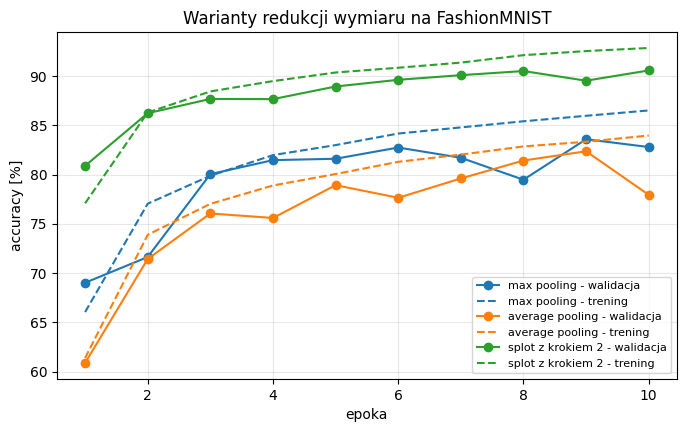

In [8]:
epochs = range(1, EPOCHS + 1)
plt.figure(figsize=(8, 4.5))
colors = ["tab:blue", "tab:orange", "tab:green"]
for (name, (_, hist, _)), color in zip(results.items(), colors):
    plt.plot(epochs, [a * 100 for a in hist["val_acc"]], "o-",
             color=color, label=f"{name} - walidacja")
    plt.plot(epochs, [a * 100 for a in hist["train_acc"]], "--",
             color=color, label=f"{name} - trening")
plt.xlabel("epoka")
plt.ylabel("accuracy [%]")
plt.title("Warianty redukcji wymiaru na FashionMNIST")
plt.legend(fontsize=8)
plt.grid(alpha=0.3)
plt.show()